# Negative loadings: where they come from and what they carry

MVSA constrains the abundances (non-negative, summing to one) but not the
endmembers, so archetype loadings can be negative. This notebook documents
that at $p = 4$ and tests one explanation, for the paper outline
(`voting-unmixing-ph-paper/outline-organized.tex`, Methods 3.2 and Results
on MVSA vs NMF, table `tab:neg`).

1. **Where the negative loadings are** (trial-mean loadings from the sweep).
2. **Reproduce the reference runs** of the sweep (MVSA and NMF, $p=4$) from the
   raw returns, to get matched endmembers *and* per-precinct abundances.
3. **Are reconstructed vote shares non-negative?**
4. **Ballot-width hypothesis.** Under valid-ballot normalization a precinct's
   vector sums to its mean number of names per ballot; since abundances sum
   to one, the reconstructed width is $\sum_k s_k c_k$ with $c_k$ the
   archetype column sums. Hypothesis: the mostly-negative archetype carries
   precinct-to-precinct variation in ballot width (row-max years: vote
   spread relative to the top candidate) rather than a slate.
5. **NMF cannot represent ballot width.** NMF columns are rescaled to a common
   sum and SUNSAL forces abundances to sum to one, so every NMF reconstruction
   has the same column sum. How much of each method's squared error is the
   ballot-width mismatch?

Run time: a few minutes (one MVSA and one NMF run per year, plus SUNSAL).

In [1]:
import sys
import warnings

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

from src.config import REPO_ROOT, load_config
from src.data import load_complete
from src.data.loading import load_sweep
from src.data.preprocessing import preprocess
from src.unmixing import extract_endmembers, method_params, sunsal_mod
from src.unmixing.matching import match_to_reference

sns.set_style("whitegrid")

YEARS = ["2013", "2016", "2019", "2022", "2025"]
METHODS = {"mvsa": "MVSA", "nmf": "NMF"}
CONFIGS = {y: load_config(REPO_ROOT / "configs" / f"config_{y}.ini") for y in YEARS}
P = 4
SWEEPS = {(y, m): load_sweep(CONFIGS[y], method=m)[P] for y in YEARS for m in METHODS}


def short(label):
    return label.split(",")[0].title()


# VCA prints these on every run; they do not affect the result
warnings.filterwarnings("ignore", message="sparse_svds failed")
warnings.filterwarnings("ignore", message="SNR estimation")

## 1. Where the negative loadings are (sweep trial means)

Per archetype: number of negative loadings, how many stay negative across
trials (mean + 2 SD < 0), negative and positive mass (sums of the negative
and positive loadings), and the column sum.

In [2]:
rows = []
for y in YEARS:
    L = SWEEPS[(y, "mvsa")]["loadings_mean"]
    S = SWEEPS[(y, "mvsa")]["loadings_std"]
    for a in L.columns:
        v, sd = L[a], S[a]
        rows.append(
            {
                "year": y,
                "archetype": a,
                "n negative": int((v < 0).sum()),
                "robust negative": int(((v + 2 * sd) < 0).sum()),
                "negative mass": -v[v < 0].sum(),
                "positive mass": v[v > 0].sum(),
                "column sum": v.sum(),
                "top positive": " / ".join(short(i) for i in v.nlargest(3).index),
                "most negative": ", ".join(
                    f"{short(i)} {v[i]:.2f}" for i in v.nsmallest(3).index if v[i] < 0
                ),
            }
        )
neg = pd.DataFrame(rows)
neg.round(2)

,year,archetype,n negative,robust negative,negative mass,positive mass,column sum,top positive,most negative
0,2013,arch_0,3,0,0.51,24.56,24.05,Hontiveros / Aquino / Magsaysay,"Binay -0.30, Ejercito Estrada -0.12, Enrile -0.09"
1,2013,arch_1,15,4,5.17,0.60,-4.57,Poe / Escudero / Legarda,"Zubiri -0.75, Ejercito Estrada -0.56, Gordon -..."
2,2013,arch_2,0,0,-0.00,19.70,19.70,Ejercito Estrada / Honasan / Binay,
3,2013,arch_3,9,2,3.20,6.37,3.17,Binay / Zubiri / Enrile,"Hontiveros -0.71, Trillanes -0.62, Escudero -0.58"
4,2016,arch_0,10,3,1.66,14.43,12.76,Drilon / De Lima / Pangilinan,"Romualdez -0.53, Romulo -0.26, Belgica -0.26"
5,2016,arch_1,2,1,0.84,16.53,15.69,Zubiri / Tolentino / Gordon,"Lapid -0.82, Pangilinan -0.01"
6,2016,arch_2,28,9,8.23,1.09,-7.14,Romualdez / Petilla / Lapid,"Osmeña -0.83, Hontiveros -0.66, De Lima -0.63"
7,2016,arch_3,1,0,0.31,24.21,23.90,Sotto / Villanueva / Lacson,Petilla -0.31
8,2019,arch_0,9,1,1.42,14.65,13.23,Dela Rosa / Go / Tolentino,"Lapid -0.40, Roxas -0.33, Bong Revilla -0.20"
9,2019,arch_1,9,6,3.11,16.61,13.50,Marcos / Bong Revilla / Lapid,"Gutoc -0.79, Diokno -0.46, Alejano -0.42"


In [3]:
per_year = neg.groupby("year")[["n negative", "robust negative"]].sum()
per_year["loadings in total"] = [SWEEPS[(y, "mvsa")]["loadings_mean"].size for y in per_year.index]
per_year

,n negative,robust negative,loadings in total
year,,,
2013,27,6,76
2016,41,13,128
2019,52,19,128
2022,58,52,136
2025,88,76,168


In [4]:
# The mostly-negative archetype of each year (negative column sum)
mostly_neg = neg[neg["column sum"] < 0].set_index("year")
others = neg[neg["column sum"] >= 0].groupby("year")["column sum"].agg(["min", "max"])
mostly_neg.join(others.add_prefix("others' column sum ")).round(2)

,archetype,n negative,robust negative,negative mass,positive mass,column sum,top positive,most negative,others' column sum min,others' column sum max
year,,,,,,,,,,
2013,arch_1,15,4,5.17,0.60,-4.57,Poe / Escudero / Legarda,"Zubiri -0.75, Ejercito Estrada -0.56, Gordon -...",3.17,24.05
2016,arch_2,28,9,8.23,1.09,-7.14,Romualdez / Petilla / Lapid,"Osmeña -0.83, Hontiveros -0.66, De Lima -0.63",12.76,23.90
2019,arch_3,26,11,9.52,0.53,-8.99,Gutoc / Bong Revilla / Roxas,"Cayetano -0.78, Marcos -0.72, Angara -0.70",12.66,13.50
2022,arch_3,28,26,5.12,0.58,-4.54,Padilla / Del Rosario / Pimentel,"Gatchalian -0.43, Eleazar -0.36, Villanueva -0.34",7.35,16.94
2025,arch_2,38,33,10.50,0.64,-9.86,Revillame / Tulfo / Pacquiao,"Go -0.82, Marcoleta -0.77, Dela Rosa -0.67",11.06,16.44


## 2. Reproduce the sweep's reference runs

The sweep's reference trial is the lowest-RMSE trial, seeded
`base_seed + reference_trial`. We rerun it with the preprocessing recorded in
the sweep's `meta.json` (not the current config, which may have changed
since), then align its archetypes to the trial-mean loadings by cosine.

Per-trial results can differ at float level between machines (notebook 09
caveat), so check the RMSE and matched cosine columns before trusting the
rest.

In [5]:
RAW = {y: load_complete(CONFIGS[y]) for y in YEARS}
PRE_KEYS = ["excluded_regions", "sen_col_start", "min_candidate_25th_percentile",
            "min_precinct_votes", "normalization"]


def reference_run(y, m):
    meta = SWEEPS[(y, m)]["meta"]
    pre = preprocess(RAW[y], verbose=False, **{k: meta["preprocessing"][k] for k in PRE_KEYS})
    unmix = CONFIGS[y]["unmixing"]
    params = meta.get("method_params") or method_params(unmix, m)
    seed = meta["base_seed"] + meta["reference_trial"]
    M = extract_endmembers(pre.Y, P, seed, m, params)
    A, _, _ = sunsal_mod(
        M, pre.Y, positivity="yes", addone="yes",
        AL_iters=unmix.getint("sunsal_al_iters"), lambda_=0.0,
        tol=unmix.getfloat("sunsal_tol"), verbose="no",
    )
    # align to the sweep's trial-mean loadings
    Lm = SWEEPS[(y, m)]["loadings_mean"]
    assert list(Lm.index) == list(pre.candidate_labels), "candidate order differs from sweep"
    perm, cos = match_to_reference(Lm.to_numpy(), M, similarity="cosine")
    M, A = M[:, perm], A[perm, :]
    rmse = float(np.sqrt(np.mean((pre.Y - M @ A) ** 2)))
    return {
        "pre": pre,
        "M": pd.DataFrame(M, index=Lm.index, columns=Lm.columns),
        "A": A,
        "rmse": rmse,
        "rmse_sweep_ref": meta["rmse_trials"][meta["reference_trial"]],
        "cos_to_mean": cos,
    }


RUNS = {}
for y in YEARS:
    for m in METHODS:
        RUNS[(y, m)] = reference_run(y, m)
        r = RUNS[(y, m)]
        print(f"{y} {METHODS[m]:4s}  N={r['pre'].Y.shape[1]:6d}  RMSE {r['rmse']:.6f} "
              f"(sweep ref {r['rmse_sweep_ref']:.6f})  min cos to trial mean {r['cos_to_mean'].min():.3f}")

2013 MVSA  N= 59675  RMSE 0.103927 (sweep ref 0.103927)  min cos to trial mean 0.975


2013 NMF   N= 59675  RMSE 0.127904 (sweep ref 0.127904)  min cos to trial mean 0.954


2016 MVSA  N= 22985  RMSE 0.099289 (sweep ref 0.099289)  min cos to trial mean 0.952


2016 NMF   N= 22985  RMSE 0.122015 (sweep ref 0.122015)  min cos to trial mean 0.984


2019 MVSA  N= 85113  RMSE 0.059389 (sweep ref 0.059389)  min cos to trial mean 0.687


2019 NMF   N= 85113  RMSE 0.085609 (sweep ref 0.085609)  min cos to trial mean 0.993


2022 MVSA  N=105033  RMSE 0.059270 (sweep ref 0.059270)  min cos to trial mean 0.962


2022 NMF   N=105033  RMSE 0.079503 (sweep ref 0.079503)  min cos to trial mean 0.987


2025 MVSA  N= 92486  RMSE 0.047645 (sweep ref 0.047645)  min cos to trial mean 0.975


2025 NMF   N= 92486  RMSE 0.060372 (sweep ref 0.060372)  min cos to trial mean 0.985


## 3. Are reconstructed vote shares non-negative?

A negative loading is harmless for the fit as long as $\mathbf{M}\mathbf{s}$
stays non-negative. Count the precinct $\times$ candidate entries where it does not.

In [6]:
rows = []
for (y, m), r in RUNS.items():
    R = r["M"].to_numpy() @ r["A"]
    rows.append(
        {
            "year": y,
            "method": METHODS[m],
            "entries < 0 (%)": 100 * (R < 0).mean(),
            "precincts with any entry < 0 (%)": 100 * (R < 0).any(axis=0).mean(),
            "most negative reconstructed share": R.min(),
        }
    )
recon = pd.DataFrame(rows).set_index(["year", "method"]).sort_index()
recon.round(4)

entries < 0 (%)  precincts with any entry < 0 (%)  \
year method                                                      
2013 MVSA             0.0989                            0.9200   
     NMF              0.0000                            0.0000   
2016 MVSA             0.2553                            5.3731   
     NMF              0.0000                            0.0000   
2019 MVSA             2.0500                           22.2246   
     NMF              0.0000                            0.0000   
2022 MVSA             0.8951                           10.8652   
     NMF              0.0000                            0.0000   
2025 MVSA             2.3188                           18.8948   
     NMF              0.0000                            0.0000   

             most negative reconstructed share  
year method                                     
2013 MVSA                              -0.2875  
     NMF                                0.0068  
2016 MVSA                              -0.2490  
     NMF                                0.0055  
2019 MVSA                              -0.3213  
     NMF                                0.0000  
2022 MVSA                              -0.2819  
     NMF                                0.0000  
2025 MVSA                              -0.2306  
     NMF                                0.0000

## 4. Ballot-width hypothesis (MVSA)

$w_i = \sum_j Y_{ji}$ is precinct $i$'s mean number of names per ballot
(2019--2025, valid-ballot normalization) or its total relative to the top
candidate (2013, 2016, row-max). Correlate each archetype's abundance with
$w$; the hypothesis predicts a strong negative correlation for the
mostly-negative archetype.

In [7]:
rows = []
for y in YEARS:
    r = RUNS[(y, "mvsa")]
    Y, A, M = r["pre"].Y, r["A"], r["M"]
    w = Y.sum(axis=0)
    csum = M.sum(axis=0)
    for k, a in enumerate(M.columns):
        rows.append(
            {
                "year": y,
                "normalization": r["pre"].params["normalization"],
                "archetype": a,
                "column sum": csum[a],
                "Pearson r(s_k, w)": pearsonr(A[k], w)[0],
                "Spearman r(s_k, w)": spearmanr(A[k], w)[0],
                "mean abundance": A[k].mean(),
            }
        )
bw = pd.DataFrame(rows)
bw.round(3)

,year,normalization,archetype,column sum,"Pearson r(s_k, w)","Spearman r(s_k, w)",mean abundance
0,2013,row_max,arch_0,27.340,0.712,0.692,0.252
1,2013,row_max,arch_1,-5.384,-0.630,-0.603,0.238
2,2013,row_max,arch_2,21.446,0.408,0.247,0.262
3,2013,row_max,arch_3,1.681,-0.271,-0.138,0.247
4,2016,row_max,arch_0,7.674,-0.205,-0.172,0.250
5,2016,row_max,arch_1,21.272,0.459,0.512,0.251
6,2016,row_max,arch_2,-8.999,-0.818,-0.763,0.248
7,2016,row_max,arch_3,31.345,0.679,0.539,0.252
8,2019,valid_ballots,arch_0,14.795,0.617,0.651,0.238
9,2019,valid_ballots,arch_1,19.105,0.617,0.572,0.256


In [8]:
# Distribution of w per year (names per ballot for 2019-2025)
pd.DataFrame(
    {
        y: pd.Series(RUNS[(y, "mvsa")]["pre"].Y.sum(axis=0)).describe(percentiles=[0.05, 0.5, 0.95])
        for y in YEARS
    }
).round(2)

,2013,2016,2019,2022,2025
count,59675.00,22985.00,85113.00,105033.00,92486.00
mean,11.65,12.91,7.12,7.03,6.47
std,1.62,2.21,1.79,1.69,1.51
min,1.00,1.00,0.15,0.34,0.03
5%,8.57,8.48,3.87,3.93,3.96
50%,11.95,13.38,7.27,7.21,6.45
95%,13.62,15.57,9.61,9.30,8.84
max,15.82,18.72,11.92,11.91,11.99


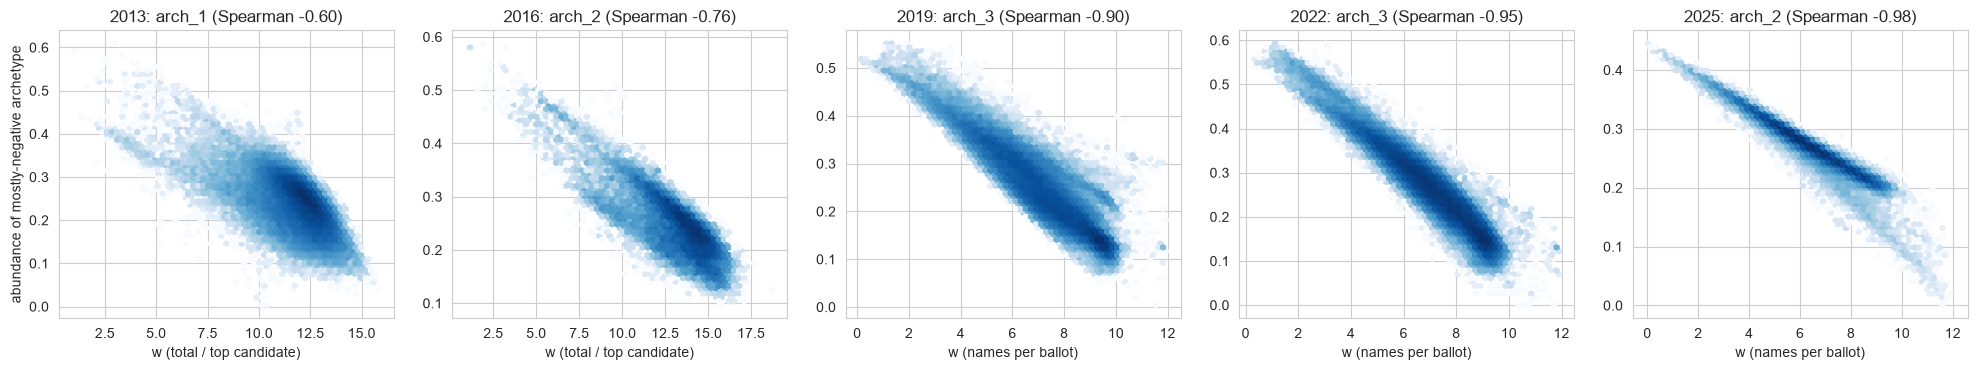

In [9]:
fig, axes = plt.subplots(1, len(YEARS), figsize=(20, 3.8))
for ax, y in zip(axes, YEARS):
    r = RUNS[(y, "mvsa")]
    k = int(np.argmin(r["M"].sum(axis=0).to_numpy()))
    w = r["pre"].Y.sum(axis=0)
    ax.hexbin(w, r["A"][k], gridsize=60, bins="log", cmap="Blues", mincnt=1)
    rho = spearmanr(r["A"][k], w)[0]
    ax.set(title=f"{y}: {r['M'].columns[k]} (Spearman {rho:.2f})",
           xlabel="w (names per ballot)" if r["pre"].params["normalization"] == "valid_ballots"
           else "w (total / top candidate)")
axes[0].set_ylabel("abundance of mostly-negative archetype")
plt.tight_layout()

In [10]:
# Where is the mostly-negative archetype abundant? (top provinces by mean abundance)
tops = {}
for y in YEARS:
    r = RUNS[(y, "mvsa")]
    k = int(np.argmin(r["M"].sum(axis=0).to_numpy()))
    geo = r["pre"].df_geo.assign(s=r["A"][k])
    g = geo.groupby(["REGION", "PROVINCE"])["s"].agg(["mean", "size"])
    tops[y] = g[g["size"] >= 30].sort_values("mean", ascending=False).head(5).round(3)
pd.concat(tops, names=["year"])

mean  size
year REGION      PROVINCE                            
2013 REGION V    SORSOGON                 0.397   468
     REGION III  AURORA                   0.354   150
     ARMM        BASILAN                  0.319   145
                 SULU                     0.313   224
     REGION V    CAMARINES NORTE          0.304   373
2016 REGION VIII LEYTE                    0.397   490
                 BILIRAN                  0.393    37
     REGION XII  SARANGANI                0.385    68
     REGION VIII EASTERN SAMAR            0.354   110
     REGION I    ILOCOS NORTE             0.339   253
2019 BARMM       MAGUINDANAO              0.435   899
                 SULU                     0.414   531
                 LANAO DEL SUR            0.413  1085
                 TAWI-TAWI                0.396   329
     REGION XI   DAVAO OCCIDENTAL         0.390   194
2022 BARMM       LANAO DEL SUR            0.453  1138
                 BASILAN                  0.445   479
                 TAWI-TAWI                0.438   402
                 MAGUINDANAO              0.411  1405
     REGION XI   DAVAO OCCIDENTAL         0.389   314
2025 BARMM       SPECIAL GEOGRAPHIC AREA  0.330   138
                 TAWI-TAWI                0.329   354
                 BASILAN                  0.318   402
     REGION I    ILOCOS NORTE             0.315   706
     REGION IX   ZAMBOANGA DEL NORTE      0.313  1102

## 5. Share of squared error that is ballot-width mismatch

Split each precinct's residual $\mathbf{e}_i = \mathbf{y}_i - \mathbf{M}\mathbf{s}_i$
into its component along the all-ones direction and the rest. The all-ones
part has squared norm $(\mathbf{1}^\top\mathbf{e}_i)^2 / L$, i.e. the error in
total width spread evenly over the $L$ candidates. For NMF the reconstructed
width is the same constant $c$ for every precinct, so $\mathbf{1}^\top\mathbf{e}_i = w_i - c$.

In [11]:
rows = []
for (y, m), r in RUNS.items():
    Y, A, M = r["pre"].Y, r["A"], r["M"].to_numpy()
    L = Y.shape[0]
    E = Y - M @ A
    width_err = E.sum(axis=0)
    sse = (E ** 2).sum()
    sse_width = (width_err ** 2).sum() / L
    recon_w = (M @ A).sum(axis=0)
    rows.append(
        {
            "year": y,
            "method": METHODS[m],
            "RMSE": np.sqrt(sse / E.size),
            "RMSE without width part": np.sqrt((sse - sse_width) / E.size),
            "width share of SSE (%)": 100 * sse_width / sse,
            "SD of data width": Y.sum(axis=0).std(),
            "SD of reconstructed width": recon_w.std(),
            "corr(reconstructed, data width)": np.corrcoef(recon_w, Y.sum(axis=0))[0, 1]
            if recon_w.std() > 1e-9 else np.nan,
        }
    )
werr = pd.DataFrame(rows).set_index(["year", "method"]).sort_index()
werr.round(4)

RMSE  RMSE without width part  width share of SSE (%)  \
year method                                                            
2013 MVSA    0.1039                   0.1037                  0.3531   
     NMF     0.1279                   0.0955                 44.2801   
2016 MVSA    0.0993                   0.0982                  2.2042   
     NMF     0.1220                   0.1006                 31.9653   
2019 MVSA    0.0594                   0.0589                  1.7073   
     NMF     0.0856                   0.0649                 42.5996   
2022 MVSA    0.0593                   0.0588                  1.5012   
     NMF     0.0795                   0.0621                 38.9526   
2025 MVSA    0.0476                   0.0472                  1.7725   
     NMF     0.0604                   0.0485                 35.5019   

             SD of data width  SD of reconstructed width  \
year method                                                
2013 MVSA              1.6171                     1.6128   
     NMF               1.6171                     0.0006   
2016 MVSA              2.2071                     2.1561   
     NMF               2.2071                     0.0027   
2019 MVSA              1.7881                     1.7708   
     NMF               1.7881                     0.0022   
2022 MVSA              1.6871                     1.6689   
     NMF               1.6871                     0.0018   
2025 MVSA              1.5111                     1.4874   
     NMF               1.5111                     0.0018   

             corr(reconstructed, data width)  
year method                                   
2013 MVSA                             0.9974  
     NMF                             -0.0369  
2016 MVSA                             0.9769  
     NMF                             -0.1466  
2019 MVSA                             0.9903  
     NMF                              0.0455  
2022 MVSA                             0.9892  
     NMF                              0.0305  
2025 MVSA                             0.9843  
     NMF                              0.1423

## 6. Table for the outline (`tab:neg`)

In [12]:
rows = []
for y in YEARS:
    mn = mostly_neg.loc[y]
    r = RUNS[(y, "mvsa")]
    k = list(r["M"].columns).index(mn["archetype"])
    w = r["pre"].Y.sum(axis=0)
    rows.append(
        {
            "year": y,
            "normalization": r["pre"].params["normalization"],
            "archetype (top positive)": f"{mn['archetype']} {mn['top positive']}",
            "neg / pos mass": f"{mn['negative mass']:.2f} / {mn['positive mass']:.2f}",
            "column sum (trial mean)": round(mn["column sum"], 2),
            "column sum (reference run)": round(r["M"].iloc[:, k].sum(), 2),
            "others' column sums": f"{others.loc[y, 'min']:.1f} to {others.loc[y, 'max']:.1f}",
            "data mean width": round(w.mean(), 2),
            "Spearman r(s, w)": round(spearmanr(r["A"][k], w)[0], 2),
            "MVSA precincts with a negative share (%)": round(recon.loc[(y, "MVSA"), "precincts with any entry < 0 (%)"], 1),
            "NMF width share of SSE (%)": round(werr.loc[(y, "NMF"), "width share of SSE (%)"], 1),
            "MVSA width share of SSE (%)": round(werr.loc[(y, "MVSA"), "width share of SSE (%)"], 1),
        }
    )
pd.DataFrame(rows).set_index("year").T

year,2013,2016,2019,2022,2025
normalization,row_max,row_max,valid_ballots,valid_ballots,valid_ballots
archetype (top positive),arch_1 Poe / Escudero / Legarda,arch_2 Romualdez / Petilla / Lapid,arch_3 Gutoc / Bong Revilla / Roxas,arch_3 Padilla / Del Rosario / Pimentel,arch_2 Revillame / Tulfo / Pacquiao
neg / pos mass,5.17 / 0.60,8.23 / 1.09,9.52 / 0.53,5.12 / 0.58,10.50 / 0.64
column sum (trial mean),-4.57,-7.14,-8.99,-4.54,-9.86
column sum (reference run),-5.38,-9.0,-6.54,-7.24,-18.42
others' column sums,3.2 to 24.1,12.8 to 23.9,12.7 to 13.5,7.4 to 16.9,11.1 to 16.4
data mean width,11.65,12.91,7.12,7.03,6.47
"Spearman r(s, w)",-0.6,-0.76,-0.9,-0.95,-0.98
MVSA precincts with a negative share (%),0.9,5.4,22.2,10.9,18.9
NMF width share of SSE (%),44.3,32.0,42.6,39.0,35.5


## Summary

Numbers from the run above (all five years at min 25th percentile = 10 and
min precinct votes = 10).

- **Section 1:** one archetype per year has a negative trial-mean column sum:
  -4.57 / -7.14 / -8.99 / -4.54 / -9.86 (2013 ... 2025). The other archetypes'
  column sums range 3.2-24.1 / 12.8-23.9 / 12.7-13.5 / 7.4-16.9 / 11.1-16.4.
  Negative loadings: 27/76, 41/128, 52/128, 58/136, 88/168 (robust: 6, 13, 19,
  52, 76).
- **Section 2:** all ten reference runs reproduce the sweep's reference RMSE.
- **Section 3:** MVSA reconstructions have a negative entry in 0.9 / 5.4 / 22.2 /
  10.9 / 18.9 % of precincts; NMF in none.
- **Section 4:** Spearman r between the mostly-negative archetype's abundance and
  $w$: -0.60 / -0.76 / -0.90 / -0.95 / -0.98. Mean $w$: 11.65 / 12.91 / 7.12 /
  7.03 / 6.47.
- **Section 5:** width share of squared error, NMF 44.3 / 32.0 / 42.6 / 39.0 /
  35.5 %, MVSA 0.4 / 2.2 / 1.7 / 1.5 / 1.8 %. SD of NMF's reconstructed width
  0.0006-0.0027.
- **Section 6:** reference-run column sums of the mostly-negative archetype
  -5.38 / -9.00 / -6.54 / -7.24 / -18.42.
